# 02 - Model Comparison: Local Kalman Filter vs Global Probabilistic LSTM
## Inventory Demand Forecasting (M5 subset) - AML Project, Phase 1

**Question we answer:** for daily SKU demand, when is a *local* model (one Kalman filter per SKU) better, and when is a *global* model (one network trained on all SKUs) better, and do simple baselines stay competitive?

**Setup (from the PRD):** 40 SKUs of one store/category (CA_1 FOODS) | daily data | 28-day forecast horizon | 4 rolling forecast origins | same SKUs, origins and horizon for every model.

| # | Model | Type | Gives P10/P90? |
|---|---|---|---|
| 1 | Seasonal naive (lag-7, and lag-28 as a variant) | baseline | no |
| 2 | Gradient boosting (`HistGradientBoostingRegressor`) | baseline, pooled ML | no |
| 3 | Kalman filter, local linear trend (one per SKU) | local state model | yes (from state variance) |
| 3b | Kalman + weekly seasonality (our extension) | local state model | yes |
| 4 | Global LSTM with quantile loss (PRD's fallback for DeepAR) | global deep learning | yes (P10/P50/P90) |

Run `01_data_cleaning_eda.ipynb` first: it creates `data/processed/m5_clean_panel.csv`.

## 1. Literature review

| Topic | Reference | What we take from it |
|---|---|---|
| State-space filtering | Kalman (1960), *A New Approach to Linear Filtering and Prediction Problems*, J. Basic Engineering | The filter: predict the hidden state, then correct it with each new observation. Optimal for linear-Gaussian models. |
| Structural time series | Harvey (1989), *Forecasting, Structural Time Series Models and the Kalman Filter*, Cambridge Univ. Press | Writing demand as level + trend (+ seasonality) states = our local linear trend model. |
| Global probabilistic forecasting | Salinas, Flunkert, Gasthaus, Januschowski (2020), *DeepAR: Probabilistic forecasting with autoregressive recurrent networks*, Int. J. Forecasting 36(3) | Train ONE recurrent network on many related series, with item embeddings and known-in-advance covariates, and output a distribution. Our LSTM follows this idea (with direct quantile outputs instead of a sampled distribution). |
| Recurrent networks | Hochreiter & Schmidhuber (1997), *Long Short-Term Memory*, Neural Computation 9(8) | LSTM cells keep a memory over long sequences (we use a 56-day look-back). |
| Quantile regression | Koenker & Bassett (1978), *Regression Quantiles*, Econometrica 46(1) | Training with the pinball (quantile) loss makes the output an estimate of a chosen quantile. |
| Benchmark / dataset | Makridakis, Spiliotis, Assimakopoulos (2022), *The M5 accuracy competition: Results, findings, and conclusions*, Int. J. Forecasting 38(4) | M5 is the Walmart data we use. The paper reports that machine-learning methods (mainly gradient-boosted trees) did better than the statistical benchmarks. |
| Gradient boosting | Friedman (2001), *Greedy function approximation: a gradient boosting machine*, Annals of Statistics 29(5) | Trees are added one by one, each fixing the errors of the previous ones. |
| Intermittent demand | Syntetos & Boylan (2005), *The accuracy of intermittent demand estimates*, Int. J. Forecasting 21(2) | The ADI / CV2 classification (smooth, erratic, intermittent, lumpy) we use for error analysis. |
| Accuracy measures | Hyndman & Koehler (2006), *Another look at measures of forecast accuracy*, Int. J. Forecasting 22(4) | Why scale-free and aggregate measures like WAPE are used, and the problems of percentage errors when sales are 0. |
| Textbook | Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed., OTexts, 2021) | Seasonal naive benchmark, time-series cross-validation (our rolling origins). |

**Gap this project looks at:** papers usually show one model winning on average. We compare local vs global models **per type of SKU** under identical rolling backtests and also report the uncertainty (intervals), not just a point forecast.

## 2. Theory in short (for the viva)

**Rolling-origin backtest.** Instead of one train/test split we pretend to be at 4 different "today" dates (origins), 28 days apart. At each origin a model sees only the past, forecasts the next 28 days, and we compare with what really happened.

**Seasonal naive.** forecast(t) = actual(t - 7). If it is Monday, predict the last Monday. A model that cannot beat this is not useful.

**Gradient boosting.** An ensemble of small decision trees built one after another; each new tree learns the errors left by the previous ones. Input: lag/rolling/calendar features. For 28 days ahead we forecast **recursively**: predict day 1, use it as "yesterday" for day 2, etc.

**Kalman filter (local linear trend).** Hidden state $x_t = [\text{level}_t, \text{trend}_t]$.

- State equation: $x_t = F x_{t-1} + w_t$, with $F = \begin{pmatrix}1&1\\0&1\end{pmatrix}$, noise $w_t \sim N(0, Q)$
- Observation: $y_t = H x_t + v_t$, with $H = (1, 0)$, noise $v_t \sim N(0, R)$
- Predict: $\hat x_{t|t-1} = F\hat x_{t-1}$, $P_{t|t-1} = F P_{t-1} F^T + Q$
- Update: $K_t = P_{t|t-1}H^T / (H P_{t|t-1} H^T + R)$, $\hat x_t = \hat x_{t|t-1} + K_t (y_t - H\hat x_{t|t-1})$

The gain $K_t$ decides how much we trust the new observation vs our prediction (big $Q$ -> adapts fast). To forecast $h$ days we only apply the predict step $h$ times; the uncertainty $P$ grows, which gives the interval $\hat y \pm 1.28\sqrt{HPH^T+R}$ (P10-P90 of a normal distribution). Noise levels are set with a simple fixed rule (no optimiser).
*Weekly extension:* 6 extra seasonal states $s_t = -(s_{t-1}+...+s_{t-6})$ let the filter learn the weekday pattern.

**Global quantile LSTM.** One network for all 40 SKUs. Input: last 56 days (sales scaled by the SKU's recent mean + calendar features) through an LSTM, plus an item embedding and the *future* calendar features; output: P10, P50, P90 for each of the next 28 days (direct multi-horizon, no recursion). Trained with the pinball loss.

**Pinball loss** for quantile $q$: $L_q(y,\hat y) = \max\big(q\,(y-\hat y),\ (q-1)\,(y-\hat y)\big)$. For $q=0.9$ under-forecasting costs 9x more than over-forecasting, so the minimiser is the 90th percentile.

**Metrics.** MAE = mean $|y-\hat y|$ | RMSE = $\sqrt{\text{mean}(y-\hat y)^2}$ (punishes big misses) | WAPE = $\sum|y-\hat y| / \sum y$ | Coverage = share of actuals inside [P10, P90] (ideal: 80%).

## 3. Setup and data overview

In [1]:
import os, sys, time
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data, features, baselines, kalman, global_model, backtest, metrics, plots

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
FIG = "../outputs/figures/"

In [2]:
panel = data.load_clean_panel("../data/processed/m5_clean_panel.csv")
wide = data.to_wide(panel)                 # rows = dates, columns = SKUs, values = sales
cal = features.make_calendar_features(panel)

origins = backtest.get_origins(len(wide))  # positions in the date index
print("SKUs:", wide.shape[1], "| days:", wide.shape[0], "| period:", wide.index[0].date(), "to", wide.index[-1].date())
overview = pd.DataFrame({
    "origin #": range(1, len(origins) + 1),
    "train until": [wide.index[o - 1].date() for o in origins],
    "train days": origins,
    "forecast from": [wide.index[o].date() for o in origins],
    "forecast to": [wide.index[o + 27].date() for o in origins]})
overview

SKUs: 40 | days: 1941 | period: 2011-01-29 to 2016-05-22


,origin #,train until,train days,forecast from,forecast to
0,1,2016-01-31,1829,2016-02-01,2016-02-28
1,2,2016-02-28,1857,2016-02-29,2016-03-27
2,3,2016-03-27,1885,2016-03-28,2016-04-24
3,4,2016-04-24,1913,2016-04-25,2016-05-22


## 4. Feature engineering (leakage-safe)
Features per SKU-day, from `src/features.py`:

| Feature | Meaning | Why |
|---|---|---|
| `lag_1, lag_7, lag_14, lag_28` | sales 1, 7, 14, 28 days earlier | ACF showed weekly peaks |
| `roll_mean_7, roll_mean_28` | average of the previous 7 / 28 days | recent level |
| `dayofweek, is_weekend` | weekday | strong weekly cycle |
| `month` | month | mild yearly pattern |
| `is_event, snap` | event day, SNAP day | known in advance |
| `item_code` | SKU id (categorical) | lets one pooled model learn SKU-specific levels |

**Why no leakage?** The lag columns are made with `shift(k)` (moves values k days *down*) and the rolling means are computed on `shift(1)`, so the row of day *t* only sees days before *t*.

In [3]:
table = features.make_feature_table(wide, cal)
one_sku = table[table["item_id"] == wide.columns[-1]]
print(len(table), "rows (SKU-days). Features:", features.FEATURES)
one_sku.iloc[28:36][["date", "sales"] + features.FEATURES[:6]]

77640 rows (SKU-days). Features: ['lag_1', 'lag_7', 'lag_14', 'lag_28', 'roll_mean_7', 'roll_mean_28', 'dayofweek', 'month', 'is_weekend', 'is_event', 'snap', 'item_code']


,date,sales,lag_1,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28
1159,2011-02-26,0.0,1.0,3.0,5.0,3.0,2.285714,2.357143
1199,2011-02-27,3.0,0.0,6.0,4.0,4.0,1.857143,2.250000
1239,2011-02-28,3.0,3.0,3.0,1.0,1.0,1.428571,2.214286
1279,2011-03-01,1.0,3.0,0.0,2.0,1.0,1.428571,2.285714
1319,2011-03-02,3.0,1.0,3.0,1.0,0.0,1.571429,2.285714
1359,2011-03-03,0.0,3.0,0.0,2.0,5.0,1.571429,2.392857
1399,2011-03-04,1.0,0.0,1.0,2.0,4.0,1.571429,2.214286
1439,2011-03-05,0.0,1.0,0.0,3.0,4.0,1.571429,2.107143


### 4.1 Test: no feature uses future values
We change all sales from day *t* onward (add 1000) and rebuild the features. Features of every day up to *t* must stay exactly the same.

In [4]:
t = 1500
changed = wide.copy()
changed.iloc[t:] = changed.iloc[t:] + 1000          # destroy the "future"

a = features.make_feature_table(wide, cal)
b = features.make_feature_table(changed, cal)
upto_t = a["date"] <= wide.index[t]                  # rows of day t and earlier
same = np.allclose(a.loc[upto_t, features.LAG_FEATURES], b.loc[upto_t, features.LAG_FEATURES], equal_nan=True)
print("features up to day t unchanged when the future changes:", same)
after = a["date"] == wide.index[t + 1]
print("(sanity) features of day t+1 DO change (lag_1 sees day t):",
      not np.allclose(a.loc[after, "lag_1"], b.loc[after, "lag_1"]))
assert same
leakage_test_features = same

features up to day t unchanged when the future changes: True
(sanity) features of day t+1 DO change (lag_1 sees day t): True


### 4.2 Test: metric functions on a tiny example (hand-checkable)

In [5]:
y = np.array([1.0, 2.0, 3.0]); yhat = np.array([2.0, 2.0, 2.0])
assert np.isclose(metrics.mae(y, yhat), 2 / 3)                 # (1+0+1)/3
assert np.isclose(metrics.rmse(y, yhat), np.sqrt(2 / 3))       # sqrt((1+0+1)/3)
assert np.isclose(metrics.wape(y, yhat), 2 / 6)                # 2 / (1+2+3)
assert np.isnan(metrics.wape(np.zeros(3), yhat))               # all-zero actuals -> undefined, flagged as NaN
assert np.isclose(metrics.pinball(np.array([1.0]), np.array([0.0]), 0.9), 0.9)   # under-forecast, q=0.9
assert np.isclose(metrics.pinball(np.array([0.0]), np.array([1.0]), 0.9), 0.1)   # over-forecast, q=0.9
assert metrics.coverage(y, y - 1, y + 1) == 1.0
print("all metric tests passed")

all metric tests passed


### 4.3 Test: the Kalman filter on synthetic data with a known answer
Before using the filter on real sales we check it on three series where we know the truth.

In [6]:
rng = np.random.default_rng(0)

# (a) constant level 10 + noise -> forecast should be about 10
y = 10 + rng.normal(0, 1, 300)
kf = kalman.build_model(y); kf.filter(y); mean, var = kf.forecast(5)
print("constant level 10        ->", mean.round(2))
assert abs(mean.mean() - 10) < 1
assert np.all(np.diff(var) > 0)                     # uncertainty grows with the horizon

# (b) straight line 3 + 0.5 t -> the trend state should find slope 0.5 and keep going up
y = 3 + 0.5 * np.arange(300) + rng.normal(0, 0.5, 300)
kf = kalman.build_model(y); kf.filter(y); mean, _ = kf.forecast(5)
print("line, expected", (3 + 0.5 * np.arange(300, 305)).round(1), "->", mean.round(1), "| trend state =", kf.x[1].round(3))
assert abs(kf.x[1] - 0.5) < 0.05

# (c) pure weekly sine wave -> the weekly version should repeat the pattern
y = 10 + 3 * np.sin(2 * np.pi * np.arange(364) / 7) + rng.normal(0, 0.5, 364)
kf = kalman.build_model(y, weekly=True); kf.filter(y); mean, _ = kf.forecast(7)
expected = 10 + 3 * np.sin(2 * np.pi * np.arange(364, 371) / 7)
print("weekly pattern, expected", expected.round(1), "->", mean.round(1))
assert np.abs(mean - expected).max() < 1
print("Kalman filter tests passed")

constant level 10        -> [10.   10.03 10.05 10.07 10.1 ]
line, expected [153.  153.5 154.  154.5 155. ] -> [152.6 153.1 153.6 154.1 154.5] | trend state = 0.484
weekly pattern, expected [10.  12.3 12.9 11.3  8.7  7.1  7.7] -> [ 9.8 12.3 12.8 11.1  8.6  7.   7.4]
Kalman filter tests passed


## 5. Run the rolling backtest
All 6 forecasters have the same interface, so they plug into the same `run_backtest` loop. Each returns the 28-day forecast for all 40 SKUs; the loop stores everything in one tidy table (`origin, date, step, item_id, model, actual, y_pred, p10, p90`).

The global LSTM is trained again at every origin (using only data before that origin), so this cell takes a few minutes.

In [7]:
models = {
    "Seasonal naive (lag-7)": baselines.seasonal_naive,
    "Seasonal naive (lag-28)": baselines.seasonal_naive_28,
    "Gradient boosting": baselines.gradient_boosting,
    "Kalman (level+trend)": kalman.kalman_llt,
    "Kalman (+weekly)": kalman.kalman_llt_weekly,
    "Global LSTM (quantile)": global_model.global_lstm,
}

start = time.time()
preds = backtest.run_backtest(wide, cal, models, origins)
print(f"backtest finished in {time.time() - start:.0f} s")
print(preds.shape, "= 6 models x 4 origins x 28 days x 40 SKUs =", 6 * 4 * 28 * 40)
preds.to_csv("../outputs/predictions.csv", index=False)
preds.head()

backtest finished in 239 s
(26880, 10) = 6 models x 4 origins x 28 days x 40 SKUs = 26880


,origin,date,step,item_id,model,actual,y_pred,p10,p90,cold_start
0,2016-01-31,2016-02-01,1,FOODS_1_034,Seasonal naive (lag-7),0.0,1.0,NaN,NaN,False
1,2016-01-31,2016-02-01,1,FOODS_1_055,Seasonal naive (lag-7),0.0,0.0,NaN,NaN,False
2,2016-01-31,2016-02-01,1,FOODS_1_172,Seasonal naive (lag-7),5.0,3.0,NaN,NaN,False
3,2016-01-31,2016-02-01,1,FOODS_1_174,Seasonal naive (lag-7),1.0,3.0,NaN,NaN,False
4,2016-01-31,2016-02-01,1,FOODS_1_180,Seasonal naive (lag-7),0.0,0.0,NaN,NaN,False


### 5.1 Fairness check: every model is scored on exactly the same rows

In [8]:
keys = ["origin", "date", "item_id"]
reference = preds[preds["model"] == "Seasonal naive (lag-7)"][keys + ["actual"]].reset_index(drop=True)
for name in models:
    m = preds[preds["model"] == name][keys + ["actual"]].reset_index(drop=True)
    assert m.equals(reference), name
print("OK - same SKUs, same origins, same 28-day windows, same actuals for all", len(models), "models")

OK - same SKUs, same origins, same 28-day windows, same actuals for all 6 models


### 5.2 Test: no model sees the future
End-to-end check. For one origin we **replace all actual sales after the origin by garbage** and run every model again. The forecasts must be identical to the first run.

In [9]:
end = origins[-1]
garbage = wide.copy()
garbage.iloc[end:] = 999.0                            # the future is destroyed

leak_ok = {}
for name, model in models.items():
    out_real = model(wide, cal, end, 28)["point"]
    out_garb = model(garbage, cal, end, 28)["point"]
    leak_ok[name] = np.allclose(out_real, out_garb, atol=1e-4)
    print(f"{name:26s} forecast unchanged: {leak_ok[name]}")
assert all(leak_ok.values())
leakage_test_models = all(leak_ok.values())

Seasonal naive (lag-7)     forecast unchanged: True
Seasonal naive (lag-28)    forecast unchanged: True


Gradient boosting          forecast unchanged: True


Kalman (level+trend)       forecast unchanged: True


Kalman (+weekly)           forecast unchanged: True


Global LSTM (quantile)     forecast unchanged: True


## 6. Cold-start fallback (PRD FR-6)
If a SKU has fewer than 56 days of selling history at the forecast origin, models cannot learn anything reliable. Rule in `src/backtest.py`: use **the median daily demand of the established SKUs of the same store/category, per weekday, over the last 28 days**.

None of our 40 SKUs triggers this rule (all have a long history), so we test it by *pretending* that one SKU only started selling 10 days before the origin.

In [10]:
end = origins[-1]
fallback = backtest.cold_start_forecast(wide, end)
assert len(fallback) == 28 and (fallback >= 0).all()
print("fallback forecast (first 7 days):", fallback[:7])

# pretend one SKU is brand new: erase its sales before (origin - 10 days)
pos = int((wide.iloc[end - 10:end].sum() > 0).values.argmax())    # a SKU that sold something in the last 10 days
test_sku = wide.columns[pos]
fake_new = wide.copy()
fake_new.iloc[:end - 10, pos] = 0.0
print(f"{test_sku}: history length in the fake data = {backtest.history_length(fake_new, end)[pos]} days (< {backtest.MIN_HISTORY})")

cold_preds = backtest.run_backtest(fake_new, cal, {"Seasonal naive (lag-7)": baselines.seasonal_naive,
                                                   "Kalman (+weekly)": kalman.kalman_llt_weekly}, [end])
g = cold_preds[cold_preds["item_id"] == test_sku]
for name in ["Seasonal naive (lag-7)", "Kalman (+weekly)"]:
    assert g[g["model"] == name]["cold_start"].all()
    assert np.allclose(g[g["model"] == name].sort_values("date")["y_pred"].values, fallback)
others = cold_preds[cold_preds["item_id"] != test_sku]
assert not others["cold_start"].any()
print("cold-start test passed: the new SKU gets the fallback forecast with every model, other SKUs are untouched")
cold_start_test = True

fallback forecast (first 7 days): [1. 1. 1. 1. 1. 1. 1.]
FOODS_1_055: history length in the fake data = 8 days (< 56)


cold-start test passed: the new SKU gets the fallback forecast with every model, other SKUs are untouched


## 7. Results

### 7.1 Overall comparison (all 40 SKUs, all 4 origins, all 28 days)

In [11]:
overall = backtest.summarize(preds, by=["model"]).set_index("model").loc[list(models)]
overall.round(3).to_csv("../outputs/metrics.csv")
overall.round(3)

,MAE,RMSE,WAPE,pinball_0.1,pinball_0.5,pinball_0.9,pinball_avg,coverage_P10_P90
model,,,,,,,,
Seasonal naive (lag-7),1.940,4.310,0.623,NaN,NaN,NaN,NaN,NaN
Seasonal naive (lag-28),1.992,4.511,0.639,NaN,NaN,NaN,NaN,NaN
Gradient boosting,1.763,3.672,0.566,NaN,NaN,NaN,NaN,NaN
Kalman (level+trend),2.445,6.475,0.785,0.307,1.223,0.890,0.807,0.945
Kalman (+weekly),2.108,5.025,0.676,0.304,1.054,0.837,0.732,0.950
Global LSTM (quantile),1.555,3.533,0.499,0.290,0.778,0.489,0.519,0.812


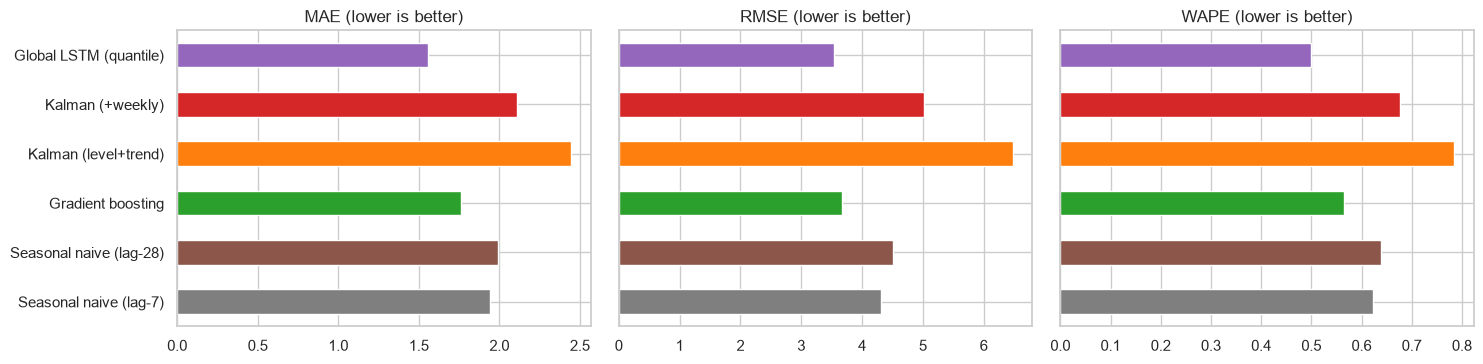

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col in zip(ax, ["MAE", "RMSE", "WAPE"]):
    overall[col].plot(kind="barh", ax=a, color=[plots.COLORS[m] for m in overall.index])
    a.set_title(col + " (lower is better)"); a.set_ylabel("")
    if a is not ax[0]:
        a.set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG + "11_model_comparison.png", dpi=120); plt.show()

### 7.2 Probabilistic forecasts: pinball loss and interval coverage
Only Kalman and the LSTM give P10/P90. Ideal coverage of the P10-P90 interval is **80%**.

In [13]:
prob = overall.dropna(subset=["pinball_avg"])[["pinball_0.1", "pinball_0.5", "pinball_0.9", "pinball_avg", "coverage_P10_P90"]]
width = preds.dropna(subset=["p10"]).assign(width=lambda d: d["p90"] - d["p10"]).groupby("model")["width"].mean()
prob = prob.assign(mean_interval_width=width)
prob.round(3)

,pinball_0.1,pinball_0.5,pinball_0.9,pinball_avg,coverage_P10_P90,mean_interval_width
model,,,,,,
Kalman (level+trend),0.307,1.223,0.890,0.807,0.945,11.111
Kalman (+weekly),0.304,1.054,0.837,0.732,0.950,10.605
Global LSTM (quantile),0.290,0.778,0.489,0.519,0.812,5.981


### 7.3 Stability across the 4 origins
A good model should not win by luck on one window only.

model,Seasonal naive (lag-7),Seasonal naive (lag-28),Gradient boosting,Kalman (level+trend),Kalman (+weekly),Global LSTM (quantile)
origin,,,,,,
2016-01-31,0.583,0.664,0.630,0.696,0.619,0.520
2016-02-28,0.557,0.611,0.529,0.687,0.578,0.481
2016-03-27,0.707,0.659,0.627,1.089,0.946,0.520
2016-04-24,0.644,0.625,0.490,0.685,0.581,0.478


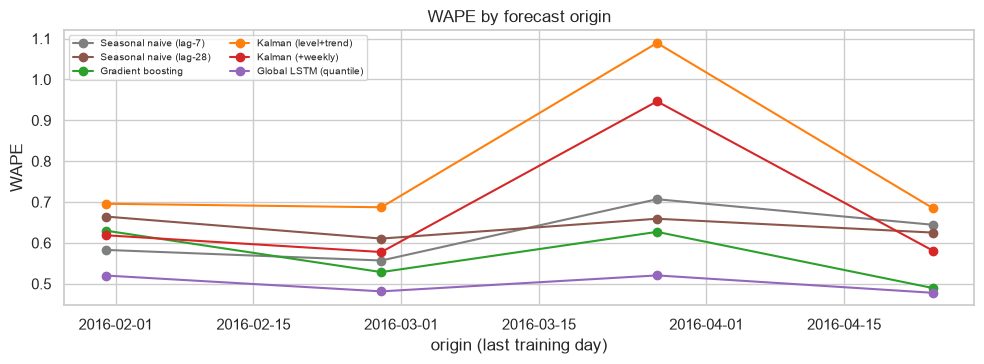

In [14]:
by_origin = backtest.summarize(preds, by=["model", "origin"])
wape_by_origin = by_origin.pivot(index="origin", columns="model", values="WAPE")[list(models)]
display(wape_by_origin.round(3))
wape_by_origin.index = [d.date() for d in wape_by_origin.index]
wape_by_origin.plot(marker="o", figsize=(10, 3.8), color=[plots.COLORS[m] for m in wape_by_origin.columns])
plt.title("WAPE by forecast origin"); plt.ylabel("WAPE"); plt.xlabel("origin (last training day)")
plt.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(FIG + "12_wape_by_origin.png", dpi=120); plt.show()

### 7.4 Per-SKU results
Aggregate numbers hide differences between SKUs, so we also look at each SKU.

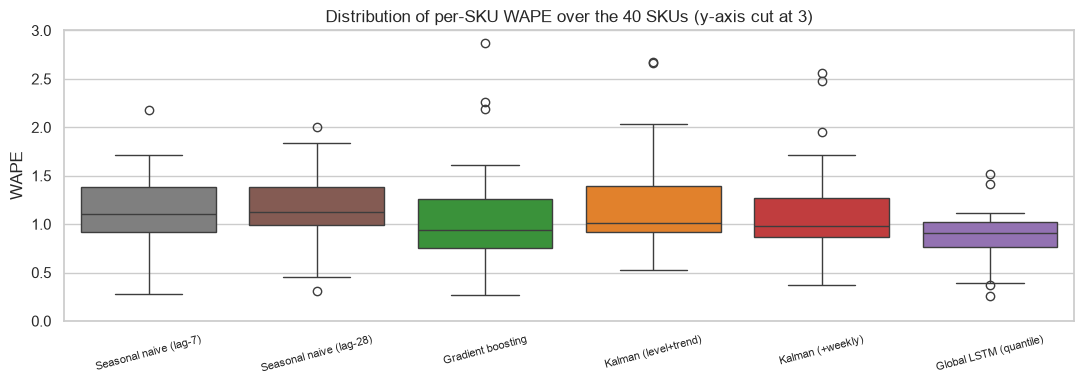

Number of SKUs for which each model has the lowest MAE:
model
Global LSTM (quantile)    31
Gradient boosting          5
Kalman (+weekly)           3
Kalman (level+trend)       1


In [15]:
by_sku = backtest.summarize(preds, by=["model", "item_id"])
by_sku.round(3).to_csv("../outputs/metrics_by_sku.csv", index=False)

plt.figure(figsize=(11, 4))
sns.boxplot(data=by_sku, x="model", y="WAPE", order=list(models), hue="model", palette=plots.COLORS, legend=False)
plt.ylim(0, 3); plt.xticks(rotation=15, fontsize=8); plt.xlabel("")
plt.title("Distribution of per-SKU WAPE over the 40 SKUs (y-axis cut at 3)")
plt.tight_layout(); plt.savefig(FIG + "13_per_sku_wape.png", dpi=120); plt.show()

best = by_sku.loc[by_sku.groupby("item_id")["MAE"].idxmin()]["model"].value_counts()
print("Number of SKUs for which each model has the lowest MAE:")
print(best.to_string())

### 7.5 Is the LSTM result just luck? (seed stability)
A neural network starts from random weights. We repeat the whole 4-origin LSTM backtest with two more seeds and compare with the other models.

In [16]:
from functools import partial

lstm_name = "Global LSTM (quantile)"
seed_rows = [overall.loc[lstm_name, ["MAE", "RMSE", "WAPE", "pinball_avg", "coverage_P10_P90"]].rename("seed 0")]
for seed in [1, 2]:
    p = backtest.run_backtest(wide, cal, {lstm_name: partial(global_model.global_lstm, seed=seed)}, origins)
    row = backtest.summarize(p).set_index("model").loc[lstm_name, ["MAE", "RMSE", "WAPE", "pinball_avg", "coverage_P10_P90"]]
    seed_rows.append(row.rename(f"seed {seed}"))
seeds = pd.DataFrame(seed_rows)
seeds.loc["mean"] = seeds.mean()
seeds.loc["std"] = seeds.iloc[:3].std()
display(seeds.round(3))
print("for comparison, best non-LSTM model (Gradient boosting): WAPE", overall.loc["Gradient boosting", "WAPE"].round(3),
      "| MAE", overall.loc["Gradient boosting", "MAE"].round(3))

,MAE,RMSE,WAPE,pinball_avg,coverage_P10_P90
seed 0,1.555,3.533,0.499,0.519,0.812
seed 1,1.572,3.662,0.504,0.515,0.818
seed 2,1.553,3.535,0.498,0.517,0.817
mean,1.560,3.577,0.501,0.517,0.816
std,0.011,0.074,0.003,0.002,0.003


for comparison, best non-LSTM model (Gradient boosting): WAPE 0.566 | MAE 1.763


## 8. Error analysis by type of SKU
Demand types are computed with the Syntetos-Boylan rule **using only the training data before the first origin** (so no future information is used).

{'intermittent': 22, 'lumpy': 9, 'smooth': 8, 'erratic': 1}

WAPE by demand class:


model,Seasonal naive (lag-7),Seasonal naive (lag-28),Gradient boosting,Kalman (level+trend),Kalman (+weekly),Global LSTM (quantile)
class,,,,,,
erratic,0.710,0.639,0.552,0.663,0.686,0.540
intermittent,0.493,0.508,0.475,0.721,0.578,0.412
lumpy,1.088,1.142,1.008,1.143,1.106,0.839
smooth,0.759,0.775,0.592,0.797,0.736,0.574


MAE by demand class:


model,Seasonal naive (lag-7),Seasonal naive (lag-28),Gradient boosting,Kalman (level+trend),Kalman (+weekly),Global LSTM (quantile)
class,,,,,,
erratic,3.759,3.384,2.922,3.512,3.634,2.858
intermittent,1.845,1.903,1.781,2.699,2.166,1.544
lumpy,1.907,2.000,1.766,2.003,1.937,1.470
smooth,2.011,2.052,1.569,2.112,1.949,1.520


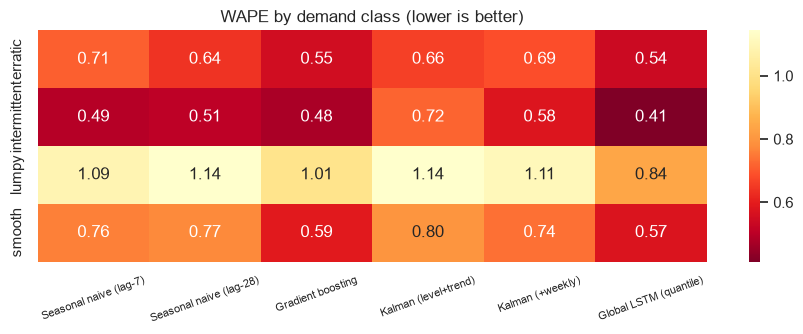

In [17]:
train_part = wide.iloc[:origins[0]]
info = []
for item in wide.columns:
    cls, adi, cv2 = data.demand_class(train_part[item].values)
    info.append({"item_id": item, "class": cls, "weekly_strength": data.weekly_strength(train_part[item]),
                 "mean_sales": train_part[item].tail(365).mean()})
sku_class = pd.DataFrame(info).set_index("item_id")
print(sku_class["class"].value_counts().to_dict())

preds["class"] = preds["item_id"].map(sku_class["class"])
by_class = backtest.summarize(preds, by=["class", "model"])
wape_class = by_class.pivot(index="class", columns="model", values="WAPE")[list(models)]
mae_class = by_class.pivot(index="class", columns="model", values="MAE")[list(models)]
print("\nWAPE by demand class:"); display(wape_class.round(3))
print("MAE by demand class:");  display(mae_class.round(3))

plt.figure(figsize=(9, 3.5))
sns.heatmap(wape_class, annot=True, fmt=".2f", cmap="YlOrRd_r")
plt.title("WAPE by demand class (lower is better)"); plt.ylabel(""); plt.xlabel("")
plt.xticks(rotation=20, fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "14_wape_by_class.png", dpi=120); plt.show()

### 8.1 Error by forecast step (does the Kalman filter adapt faster at short horizons?)

model,Seasonal naive (lag-7),Seasonal naive (lag-28),Gradient boosting,Kalman (level+trend),Kalman (+weekly),Global LSTM (quantile)
step_group,,,,,,
day 1-7,0.635,0.644,0.535,0.634,0.567,0.468
day 15-21,0.638,0.632,0.567,0.860,0.726,0.496
day 22-28,0.610,0.610,0.566,0.949,0.786,0.515
day 8-14,0.608,0.669,0.594,0.696,0.627,0.517


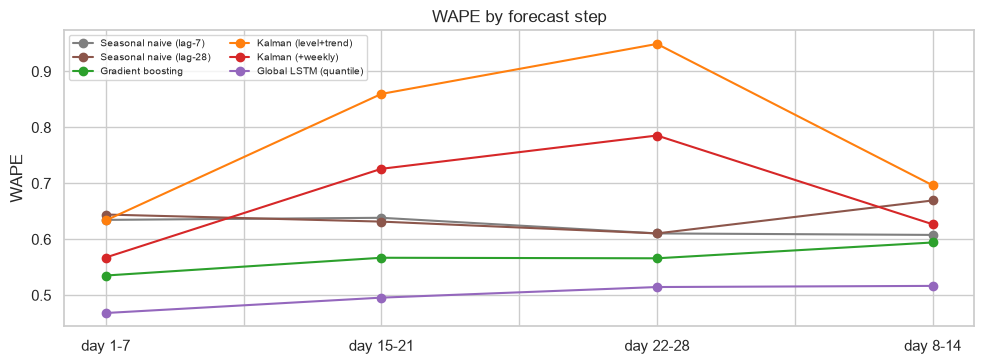

In [18]:
preds["step_group"] = pd.cut(preds["step"], [0, 7, 14, 21, 28], labels=["day 1-7", "day 8-14", "day 15-21", "day 22-28"])
by_step = backtest.summarize(preds, by=["step_group", "model"])
wape_step = by_step.pivot(index="step_group", columns="model", values="WAPE")[list(models)]
display(wape_step.round(3))
wape_step.plot(marker="o", figsize=(10, 3.8), color=[plots.COLORS[m] for m in wape_step.columns])
plt.title("WAPE by forecast step"); plt.ylabel("WAPE"); plt.xlabel("")
plt.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(FIG + "15_wape_by_step.png", dpi=120); plt.show()

### 8.2 Availability proxy as a diagnostic
The PRD asks us to keep the `potential_unavailable` flag as a diagnostic. How many test days carry the flag?

In [19]:
flags = panel[["item_id", "date", "potential_unavailable"]]
checked = preds.merge(flags, on=["item_id", "date"], how="left")
n_flagged = int(checked.loc[checked["model"] == "Seasonal naive (lag-7)", "potential_unavailable"].sum())
print("flagged SKU-days inside the 4 forecast windows:", n_flagged)
print("-> metrics with and without flagged days are identical here. The flag only marks pre-launch days in this subset (see notebook 01).")

flagged SKU-days inside the 4 forecast windows: 0
-> metrics with and without flagged days are identical here. The flag only marks pre-launch days in this subset (see notebook 01).


## 9. Forecast plots for representative SKUs
Black = actual, coloured lines = point forecasts, shaded band = P10-P90 of the **global LSTM**. We show the last origin (forecast window = the last 28 days of data).

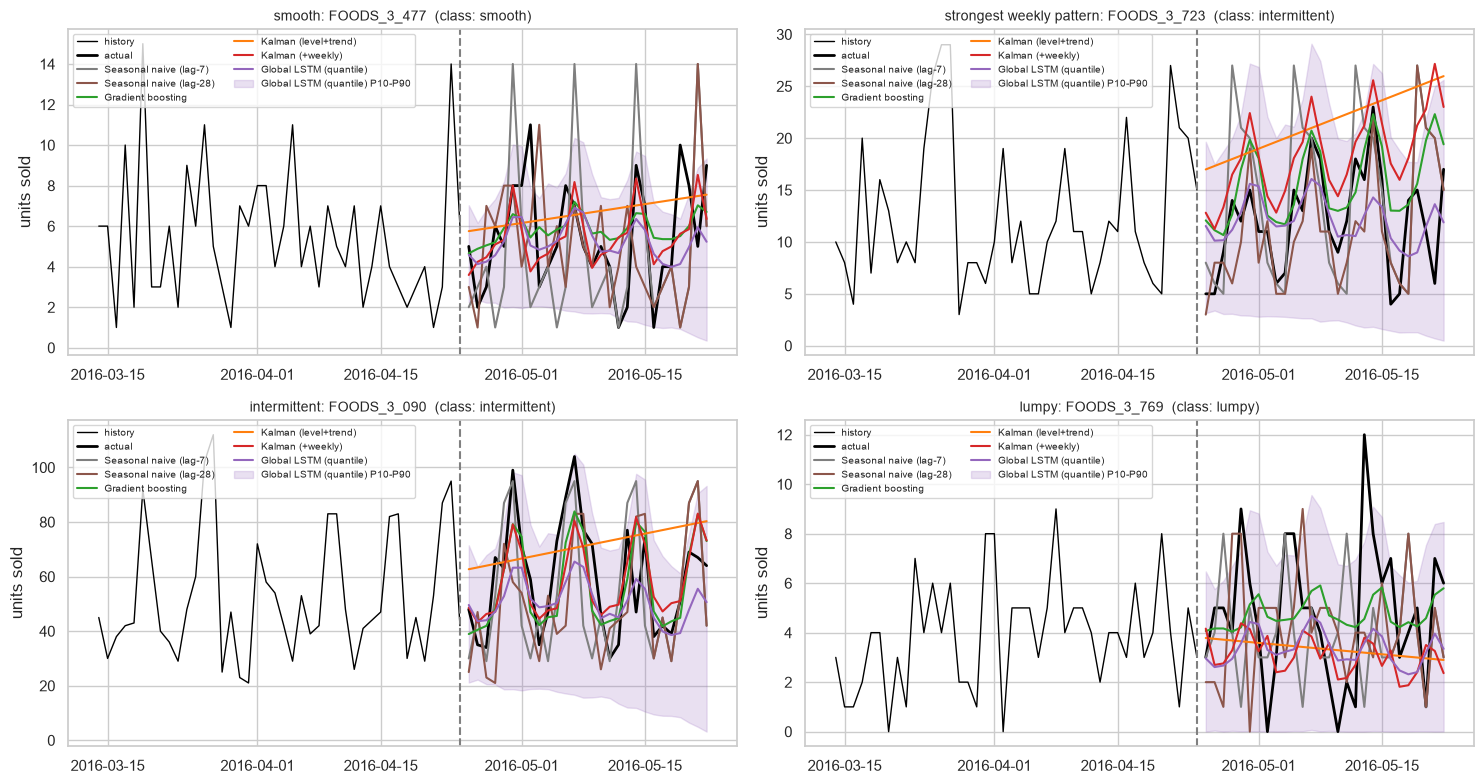

In [20]:
last_origin = wide.index[origins[-1] - 1]
point_models = list(models)
picks = {}
picks["smooth"] = sku_class[sku_class["class"] == "smooth"]["mean_sales"].idxmax()
picks["strongest weekly pattern"] = sku_class.drop(index=list(picks.values()))["weekly_strength"].idxmax()
for kind in ["intermittent", "lumpy"]:
    picks[kind] = sku_class[sku_class["class"] == kind]["mean_sales"].idxmax()
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (kind, item) in zip(axes.ravel(), picks.items()):
    plots.plot_sku_forecast(wide, preds, item, last_origin, point_models, band_model="Global LSTM (quantile)", ax=ax)
    ax.set_title(f"{kind}: {item}  (class: {sku_class.loc[item, 'class']})", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "16_sku_forecasts.png", dpi=120); plt.show()

### 9.1 Uncertainty: Kalman interval vs global LSTM interval (same SKU, same window)

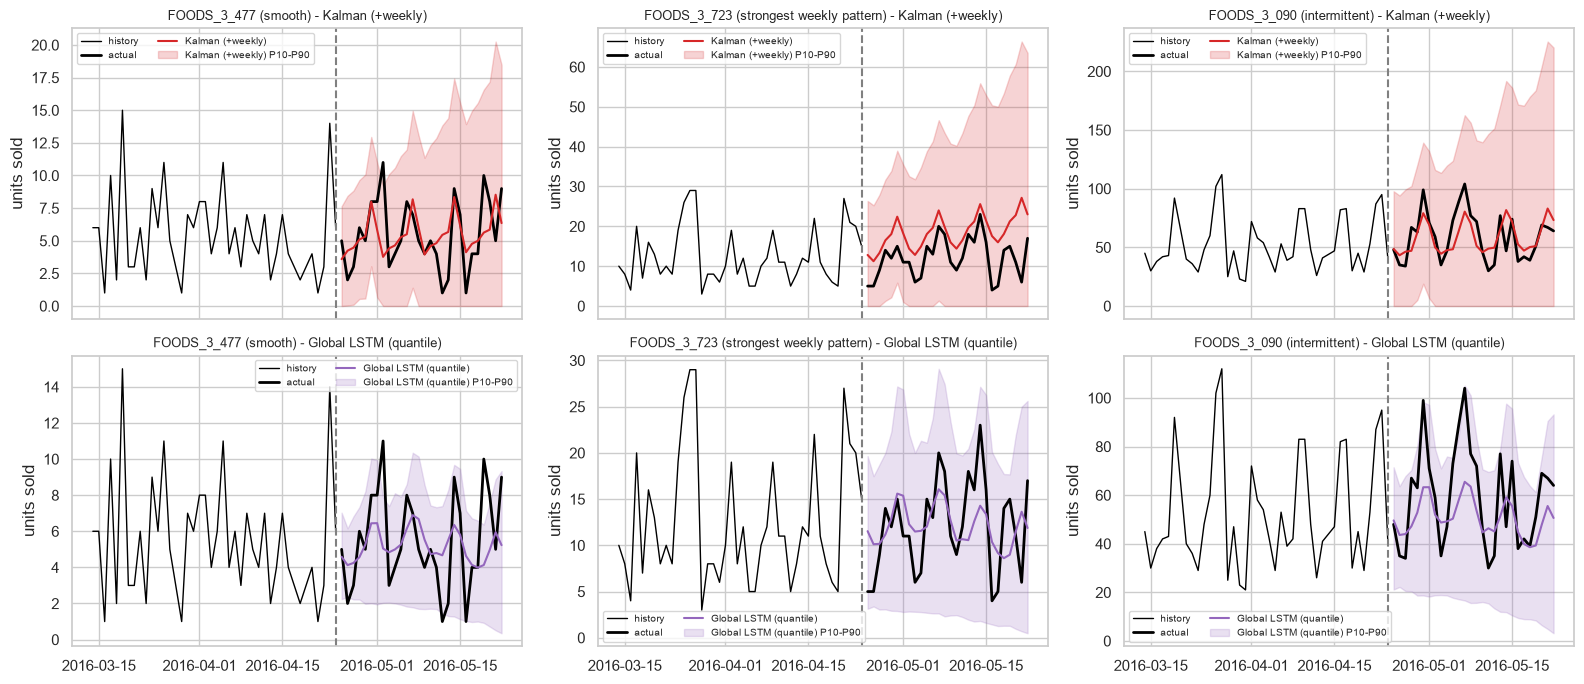

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex="col")
for col, (kind, item) in enumerate(list(picks.items())[:3]):
    for row, m in enumerate(["Kalman (+weekly)", "Global LSTM (quantile)"]):
        plots.plot_sku_forecast(wide, preds, item, last_origin, [m], band_model=m, ax=axes[row, col])
        axes[row, col].set_title(f"{item} ({kind}) - {m}", fontsize=9)
plt.tight_layout(); plt.savefig(FIG + "17_uncertainty_bands.png", dpi=120); plt.show()

### 9.2 Cold-start example (the fake new SKU from section 6)

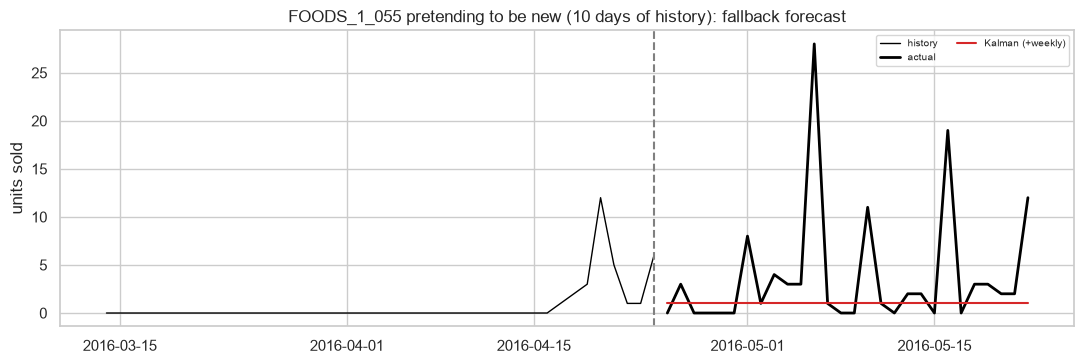

In [22]:
fig, ax = plt.subplots(figsize=(11, 3.8))
plots.plot_sku_forecast(fake_new, cold_preds, test_sku, wide.index[end - 1], ["Kalman (+weekly)"], ax=ax)
ax.set_title(f"{test_sku} pretending to be new (10 days of history): fallback forecast")
plt.tight_layout(); plt.savefig(FIG + "18_cold_start.png", dpi=120); plt.show()

## 10. Conclusion

All numbers below are from the tables above (40 SKUs, 4 origins, 28-day horizon, Feb-May 2016).

**1. The global LSTM was the best model overall.** MAE 1.555, RMSE 3.533, WAPE 0.499, lowest average pinball loss (0.519), and the lowest MAE on 31 of 40 SKUs. This is not a lucky seed: over 3 seeds WAPE was 0.501 +/- 0.003. It also won at every one of the 4 origins and in every demand class. Sharing patterns across SKUs helps most for intermittent and lumpy SKUs, where one SKU alone has little data (intermittent WAPE 0.41 vs 0.72 for the plain Kalman filter).

**2. Gradient boosting is a strong, simple baseline.** WAPE 0.566, clearly better than seasonal naive (0.623) and second best overall. So the deep model does *not* win by a huge margin over a good tabular model, and deep learning is not automatically needed.

**3. The Kalman filter did NOT beat the global model or the seasonal naive baseline overall.**
* Level+trend only: WAPE 0.785 (worst). Weekly extension: 0.676 (better, because the weekly cycle is strong), still behind seasonal naive lag-7 (0.623).
* Where it adapts well: in the first 7 days the weekly Kalman filter (WAPE 0.567) beats seasonal naive (0.635). But its error grows with the horizon (0.567 -> 0.786 by day 22-28) while the LSTM and gradient boosting stay almost flat (LSTM 0.468 -> 0.515). A local filter has no way to know about the future calendar and keeps extrapolating its latest level/trend.
* Weakness: trend extrapolation. At origin 3, one fast seller (FOODS_3_090) pushed the trend state up, and the filter forecast 2,878 units for 28 days against 1,423 actual, which alone drives its WAPE to 1.09 at that origin.
* It never had the best WAPE in any demand class, and it was best on only 4 of 40 SKUs by MAE.

**4. Uncertainty.** The LSTM's P10-P90 interval covered 81.2% of actuals (ideal 80%) with a mean width of 6.0 units. The Kalman intervals covered 94.5-95.0% with a mean width of about 11 units: they are valid but too wide to be useful (the Gaussian variance grows with the horizon and our fixed noise rule is conservative). Pinball loss agrees: the LSTM is better at all three quantiles.

**5. Hard series.** Lumpy SKUs are the hardest for every model (WAPE 0.84-1.14). For such series the intervals are more informative than any single point forecast.

**Cautions for honest interpretation**
* The LSTM predicts the *median* (P50) and MAE favours medians on count data with many zeros, while the other models predict means. The LSTM also wins on RMSE (3.53 vs 3.67 for gradient boosting), which does not favour medians, but the RMSE gap is much smaller than the MAE gap.
* Pooled metrics are dominated by the few high-volume SKUs. The per-SKU and per-class tables are the safer view.
* One subset (40 SKUs, one store), four 28-day windows, no hyper-parameter search. We claim a comparison under identical backtests, not a general ranking of methods.
* The demand classes in this notebook are computed from training data only (22 intermittent, 9 lumpy, 8 smooth, 1 erratic); notebook 01 used all data, so counts differ by one or two SKUs.

## 11. Limitations and future work
* **Subset only:** 40 SKUs of one store/category, not the whole M5. Results may differ for other stores, categories or the full data.
* **Mostly intermittent SKUs:** metrics for slow sellers are noisy (a miss of 1 unit is a large percentage), so we show WAPE together with MAE and per-class tables.
* **Availability proxy** is not a stockout label, and in this subset it only marks pre-launch days (notebook 01).
* **Global model = LSTM, not DeepAR (GluonTS).** The PRD allows this fallback. We use direct quantile outputs; DeepAR samples from a fitted distribution (e.g. negative binomial), which suits counts better.
* **Kalman noise** is set with a fixed rule, not optimised; Gaussian intervals are an approximation for count data (they can go below 0, we clip at 0).
* **No price features** in the models (prices of future weeks are not part of the PRD feature list). Adding price and promotion features is the obvious next step.
* **One random seed** for the LSTM. A more careful study would repeat training with several seeds and report the spread.
* No hyper-parameter search (PRD non-goal).

## 12. Acceptance-criteria self-check (PRD section 11)

In [23]:
checks = {
    "pipeline runs end-to-end on a limited M5 subset": preds.shape[0] == 6 * 4 * 28 * 40,
    "at least 30 SKUs, all with a complete daily index": wide.shape[1] >= 30 and wide.notna().all().all()
                                                       and (wide.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all(),
    "all models forecast the same 28-day windows": preds.groupby("model").size().nunique() == 1,
    "no lag/rolling feature uses future values (feature test)": leakage_test_features,
    "no model output changes when the future is destroyed": leakage_test_models,
    "MAE, RMSE, WAPE reported for every model": overall[["MAE", "RMSE", "WAPE"]].notna().all().all(),
    "pinball loss reported for probabilistic models": prob["pinball_avg"].notna().all() and len(prob) == 3,
    "at least 3 SKU plots with actuals, forecasts, uncertainty": len(picks) >= 3,
    "availability named as a proxy (potential_unavailable)": "potential_unavailable" in panel.columns,
    "cold-start fallback documented and tested": cold_start_test,
    "outputs saved (predictions.csv, metrics.csv, figures)": os.path.exists("../outputs/predictions.csv") and os.path.exists("../outputs/metrics.csv"),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks.values())

PASS - pipeline runs end-to-end on a limited M5 subset
PASS - at least 30 SKUs, all with a complete daily index
PASS - all models forecast the same 28-day windows
PASS - no lag/rolling feature uses future values (feature test)
PASS - no model output changes when the future is destroyed
PASS - MAE, RMSE, WAPE reported for every model
PASS - pinball loss reported for probabilistic models
PASS - at least 3 SKU plots with actuals, forecasts, uncertainty
PASS - availability named as a proxy (potential_unavailable)
PASS - cold-start fallback documented and tested
PASS - outputs saved (predictions.csv, metrics.csv, figures)
